In [317]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from LD.utils.ld_tools import *
from sklearn.cluster import KMeans
import umap
from sklearn.manifold import trustworthiness
from LD.utils.ld_tools import *
from sklearn import datasets
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.preprocessing import StandardScaler
import copy
from sklearn.cluster import DBSCAN
from sklearn.metrics import roc_auc_score
from kmeansFermat import *
# from sklearn_extra.cluster import KMedoids


In [318]:
# variables reduction
dim_reduction = 10
alpha_reduction = 7
reduction = True

# varibles clustering
classe_cible = 0
alpha_prox = 3
alpha_ext = 7
# kmeans, dbscan, kmeansF, kmedoidsF
clustering_method = 'dbscan'


## pré-traitement

In [319]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train_all = x_train.reshape(x_train.shape[0], -1) / 255.0
x_test_all = x_test.reshape(x_test.shape[0], -1) / 255.0

indices_train = np.where(y_train == classe_cible)[0][:1000]
points0 = x_train_all[indices_train]

indices_test = np.concatenate([
    np.where(y_test == classe_cible)[0][:90], 
    np.concatenate([np.where(y_test == i)[0][:10] for i in range(10) if i != classe_cible])
])
points1 = x_test_all[indices_test]

labels_test_original = y_test[indices_test].astype(int)
labels_test_binaire = (labels_test_original != classe_cible).astype(int)

scaler = StandardScaler()
points0 = scaler.fit_transform(points0)
points_test0 = scaler.transform(points1)

## Reduction UMAP

In [320]:
if reduction:
    points = copy.deepcopy(points0)
    points_test = copy.deepcopy(points_test0)
    
    umap_reducer = umap.UMAP(n_components=dim_reduction)
    umap_reducer.fit(points)
    points = umap_reducer.transform(points)
    points_test = umap_reducer.transform(points_test)
    
    dist_mat = distance_matrix(points, points)
    fermat_dist_mat = fermat_function(dist_mat, alpha=alpha_reduction)
    
    score = trustworthiness(points0, points, n_neighbors=20)
    print(f"Trustworthiness score: {score:.4f}")

Trustworthiness score: 0.9090


## Tests multi-clusteurs

In [321]:
if clustering_method == 'dbscan':
    clust = DBSCAN(eps=13, min_samples=8).fit(points)
    labels = clust.labels_
    valeurs_uniques, comptes = np.unique(labels, return_counts=True)
    # -1 c'est les valeurs considerees comme bruit
    #print(labels)
    
    list_clusters = []
    for i in range(len(valeurs_uniques)):
        if valeurs_uniques[i] != -1: 
            cluster_points = points[labels == valeurs_uniques[i]]
            list_clusters.append(cluster_points)
            
elif clustering_method == 'kmeans':
    kmeans = KMeans(n_clusters=3, random_state=0).fit(points)
    list_clusters = []
    for i in range(kmeans.n_clusters):
        cluster_points = points[kmeans.labels_ == i]
        list_clusters.append(cluster_points)
        
elif clustering_method == 'kmeansF':
    list_clusters, labels, _ = kmeans_fermat(points=points, nb_clusters=3, alpha=alpha_prox)
    
elif clustering_method == 'kmedoidsF':
    kmedoids = KMedoids(n_clusters=3, metric='precomputed', random_state=0).fit(fermat_dist_mat)
    list_clusters = []
    for i in range(kmedoids.n_clusters):
        cluster_points = points[kmedoids.labels_ == i]
        list_clusters.append(cluster_points)
    

In [ ]:
def kmeans_fermat(points, nb_clusters, alpha, max_iters=100, tol=1e-4, device='cpu'):
    N = points.shape[0]
    
    dist_mat_eucl = distance_matrix(points, points)
    fermat_dist_mat = fermat_function(dist_mat_eucl, alpha=alpha)
    
    indices_init = np.random.choice(N, size=nb_clusters, replace=False)
    centroids = points[indices_init].copy()
    
    for i in range(max_iters):
        old_centroids = centroids.copy()
        
        dist_array = distance_matrix(centroids, points)
        
        fermat_distances = fermat_function_ext_simultaneous(
            fermat_dist_mat, 
            dist_array, 
            alpha=alpha, 
            device=device
        )
        
        labels = np.argmin(fermat_distances, axis=0)
        
        for k in range(nb_clusters):
            cluster_points = points[labels == k]
            if len(cluster_points) > 0:
                centroids[k] = np.mean(cluster_points, axis=0)
            else:
                centroids[k] = points[np.random.randint(N)].copy()
                
        if np.linalg.norm(centroids - old_centroids) < tol:
            break
            
    list_clusters = [points[labels == k] for k in range(nb_clusters) if np.sum(labels == k) > 0]
    
    return list_clusters, labels, centroids

In [323]:
list_lens_depth_ext_fermat = []
d = []
for j in range(len(list_clusters)):
    dist_mat = distance_matrix(list_clusters[j],list_clusters[j])
    d.append(dist_mat)
    fermat_dist_mat = fermat_function(dist_mat,alpha= alpha_prox)
    lens_depth_ext_fermat = []
    for i in range(points_test.shape[0]):
        dist_array = distance_matrix(list_clusters[j],points_test[i].reshape((1,-1)))
        dist_ext = fermat_function_ext(fermat_dist_mat, dist_array, alpha= alpha_ext)
        lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]
    list_lens_depth_ext_fermat += [np.array(lens_depth_ext_fermat)]
    
list_lens_depth_ext_fermat = np.array(list_lens_depth_ext_fermat)
lens_depth_ext_fermat_seperate = np.max(list_lens_depth_ext_fermat, axis=0)


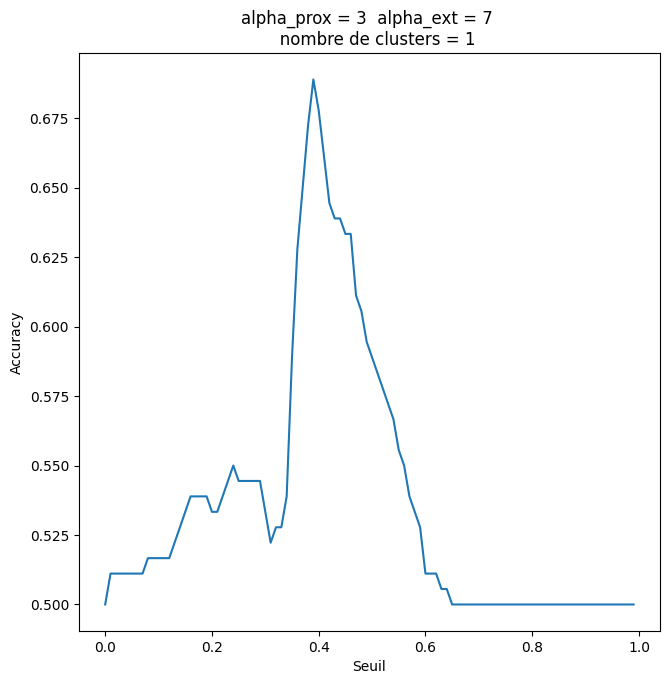

In [324]:
acc_list4 = []
for i in range(100):
    seuil = i/100
    y_pred = (np.array(lens_depth_ext_fermat_seperate) < seuil).astype(int)
    acc_list4.append(metrics.accuracy_score(labels_test_binaire, y_pred))

auc = roc_auc_score(labels_test_binaire, -lens_depth_ext_fermat_seperate)


plt.plot(np.arange(100)/100, acc_list4)
plt.xlabel("Seuil")
plt.ylabel("Accuracy")
plt.title(f"alpha_prox = {alpha_prox}  alpha_ext = {alpha_ext} \n   nombre de clusters = {len(list_clusters)}")
plt.show()

In [325]:
print(min(lens_depth_ext_fermat), max(lens_depth_ext_fermat))

0.0006166166166166167 0.6422922922922923


In [326]:
print(f"Max accuracy: {np.max(acc_list4):.4f} au seui: {np.argmax(acc_list4)/100:.2f}\nAUC: {auc}")

Max accuracy: 0.6889 au seui: 0.39
AUC: 0.7029629629629629


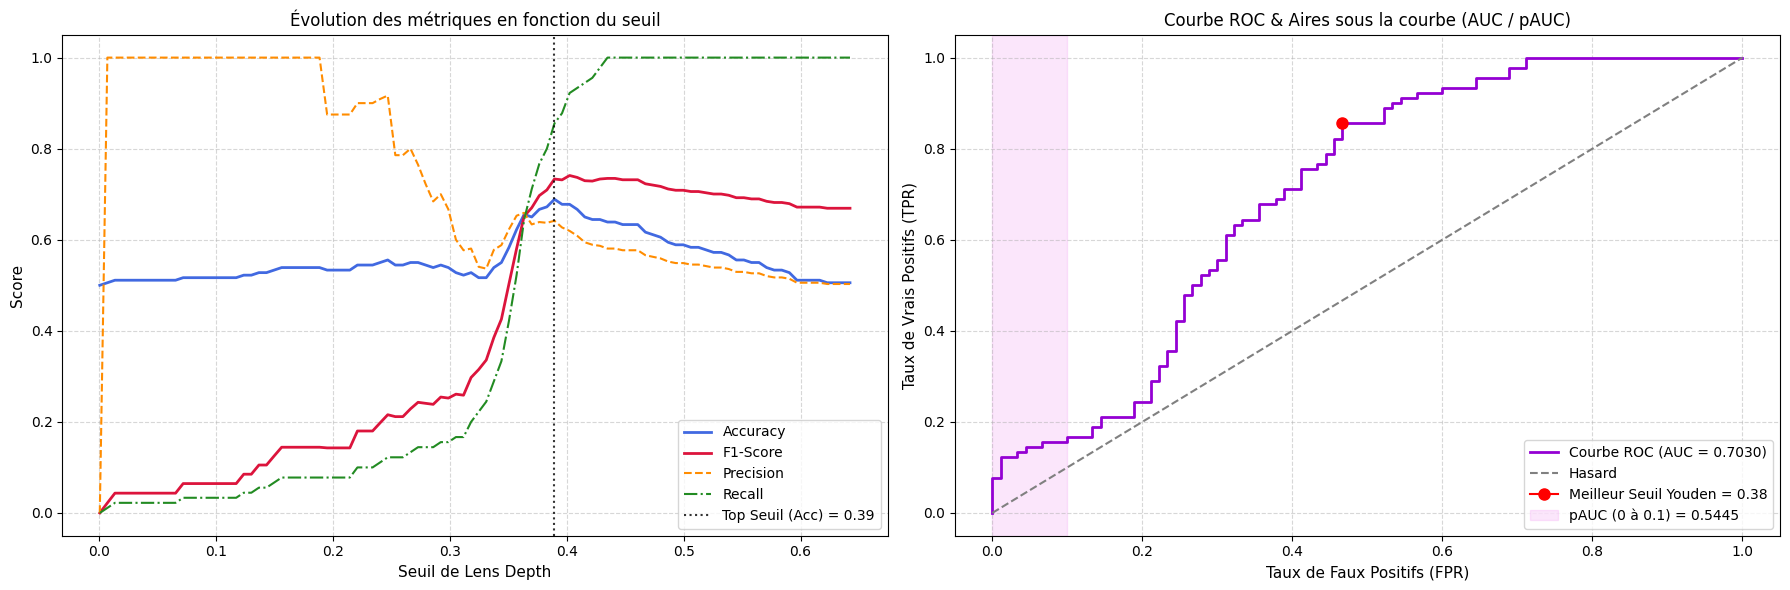

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics

y_true = labels_test_binaire
ld_scores = lens_depth_ext_fermat_seperate

min_score, max_score = np.min(ld_scores), np.max(ld_scores)
seuils = np.linspace(min_score, max_score, 100)

acc_list = []
f1_list = []
precision_list = []
recall_list = []

for seuil in seuils:
    y_pred = (ld_scores < seuil).astype(int)
    acc_list.append(metrics.accuracy_score(y_true, y_pred))
    f1_list.append(metrics.f1_score(y_true, y_pred, pos_label=1, zero_division=0))
    precision_list.append(metrics.precision_score(y_true, y_pred, pos_label=1, zero_division=0))
    recall_list.append(metrics.recall_score(y_true, y_pred, pos_label=1, zero_division=0))
    
fpr, tpr, thresholds = metrics.roc_curve(y_true, -ld_scores)
auc_score = metrics.auc(fpr, tpr)

max_fpr = 0.1
pauc_score = metrics.roc_auc_score(y_true, -ld_scores, max_fpr=max_fpr)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# --- Graphique 1 : Métriques ---
ax1.plot(seuils, acc_list, label="Accuracy", color="royalblue", lw=2)
ax1.plot(seuils, f1_list, label="F1-Score", color="crimson", lw=2)
ax1.plot(seuils, precision_list, label="Precision", color="darkorange", linestyle="--")
ax1.plot(seuils, recall_list, label="Recall", color="forestgreen", linestyle="-.")

meilleur_seuil_acc = seuils[np.argmax(acc_list)]
ax1.axvline(x=meilleur_seuil_acc, color="black", linestyle=":", alpha=0.8, 
            label=f"Top Seuil (Acc) = {meilleur_seuil_acc:.2f}")

ax1.set_xlabel("Seuil de Lens Depth", fontsize=11)
ax1.set_ylabel("Score", fontsize=11)
ax1.set_title("Évolution des métriques en fonction du seuil", fontsize=12)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(fpr, tpr, color="darkviolet", lw=2, label=f"Courbe ROC (AUC = {auc_score:.4f})")
ax2.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Hasard")

J = tpr - fpr
ix = np.argmax(J)

meilleur_seuil_youden = -thresholds[ix]
ax2.plot(fpr[ix], tpr[ix], marker='o', color='red', markersize=8, label=f"Meilleur Seuil Youden = {meilleur_seuil_youden:.2f}")

ax2.axvspan(0, max_fpr, color='violet', alpha=0.2, 
            label=f"pAUC (0 à {max_fpr}) = {pauc_score:.4f}")

ax2.set_xlabel("Taux de Faux Positifs (FPR)", fontsize=11)
ax2.set_ylabel("Taux de Vrais Positifs (TPR)", fontsize=11)
ax2.set_title("Courbe ROC & Aires sous la courbe (AUC / pAUC)", fontsize=12)
ax2.legend(loc="lower right")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()